# Noisy messages, soft decoding and modern code families

Eight actual short-code methods use independent 64-bit messages and a common Eb/N0 convention. Every encoder/decoder is tested against noiseless cases and independent algebra or likelihood oracles.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.coding import hamming_encode, hamming_decode

message = np.array([[1, 0, 1, 1]], dtype=np.uint8)
word = hamming_encode(message)
corrupted = word.copy()
corrupted[0, 2] ^= 1
restored = hamming_decode(10 * (1 - 2 * corrupted.astype(float)))
print("Message", message, "coded", word, "one flipped bit", corrupted, "decoded", restored)
assert np.array_equal(restored, message)

Message [[1 0 1 1]] coded [[0 1 1 0 0 1 1]] one flipped bit [[0 1 0 0 0 1 1]] decoded [[1 0 1 1]]


Soft LLRs retain reliability that hard decisions discard. Hamming soft ML, terminated convolutional/Viterbi, owned short IRA-LDPC sum-product/min-sum and BEC-designed Polar SC have explicit construction limits. This is not a 5G profile or a guarantee that a syndrome-valid word is correct.

In [3]:
for record, path in query("coding", ebn0_db=3):
    m = record["metrics"]
    print(
        record["config"]["method"],
        "rate",
        m["actual_rate"],
        "BER",
        m["bit_error_rate"],
        "BLER",
        m["block_error_rate"],
        "95% message interval",
        m["block_error_interval"],
    )

convolutional rate 0.45714285714285713 BER 0.00099945068359375 BLER 0.0126953125 95% message interval [0.008678265634101043, 0.01853702362747245]
hamming_hard rate 0.5714285714285714 BER 0.031951904296875 BLER 0.70068359375 95% message interval [0.6804889311532607, 0.72012681645545]
hamming_soft rate 0.5714285714285714 BER 0.01354217529296875 BLER 0.38720703125 95% message interval [0.36634034347567496, 0.4084960611530058]
ldpc_bp rate 0.5 BER 0.00199127197265625 BLER 0.02978515625 95% message interval [0.023257534422266708, 0.03807345110768847]
ldpc_min_sum rate 0.5 BER 0.001983642578125 BLER 0.037109375 95% message interval [0.02975109707082455, 0.046200901145579926]
polar_sc rate 0.5 BER 0.00484466552734375 BLER 0.02490234375 95% message interval [0.01899091364096258, 0.03259273009802641]
repetition3 rate 0.3333333333333333 BER 0.023040771484375 BLER 0.77587890625 95% message interval [0.7573117743494112, 0.7934130368401789]
uncoded rate 1.0 BER 0.02365875244140625 BLER 0.7700195312

**Recorded configuration**

{
  "family": "coding",
  "id": "ldpc_bp_1",
  "method": "ldpc_bp",
  "message_bits": 64,
  "trials": 2048,
  "ebn0_db": 1,
  "batch_size": 256,
  "max_iterations": 50,
  "graph_seed": 991,
  "design_erasure": 0.5
}
{
  "bit_error_rate": 0.04782867431640625,
  "block_error_rate": 0.51708984375,
  "block_error_interval": [
    0.495435998654789,
    0.5386796976135928
  ],
  "block_errors": 1059,
  "bit_errors": 6269,
  "trials": 2048,
  "message_bits": 64,
  "coded_bits": 128,
  "actual_rate": 0.5,
  "noise_variance": 0.7943282347242815,
  "encode_seconds": 0.011892184615135193,
  "decode_seconds": 2.5412444407120347,
  "gaussian_capacity_bits_per_real_use": 0.5878183173461944,
  "bpsk_information_bits_per_real_use": 0.5627881377511866,
  "mean_decoder_iterations": 29.50390625,
  "syndrome_satisfaction_fraction": 0.49609375,
  "scope": "Independent uniform 64-bit messages; all termination bits count in actual rate. BPSK energy/message-bit normalization gives noise variance=1/(2*actual_

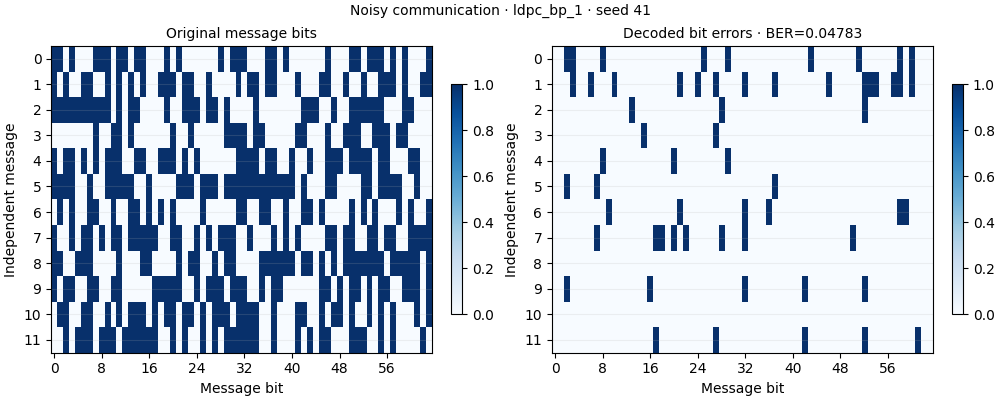

In [4]:
record, path = query("coding", method="ldpc_bp", ebn0_db=1)[0]
measured(record)
preview(record)

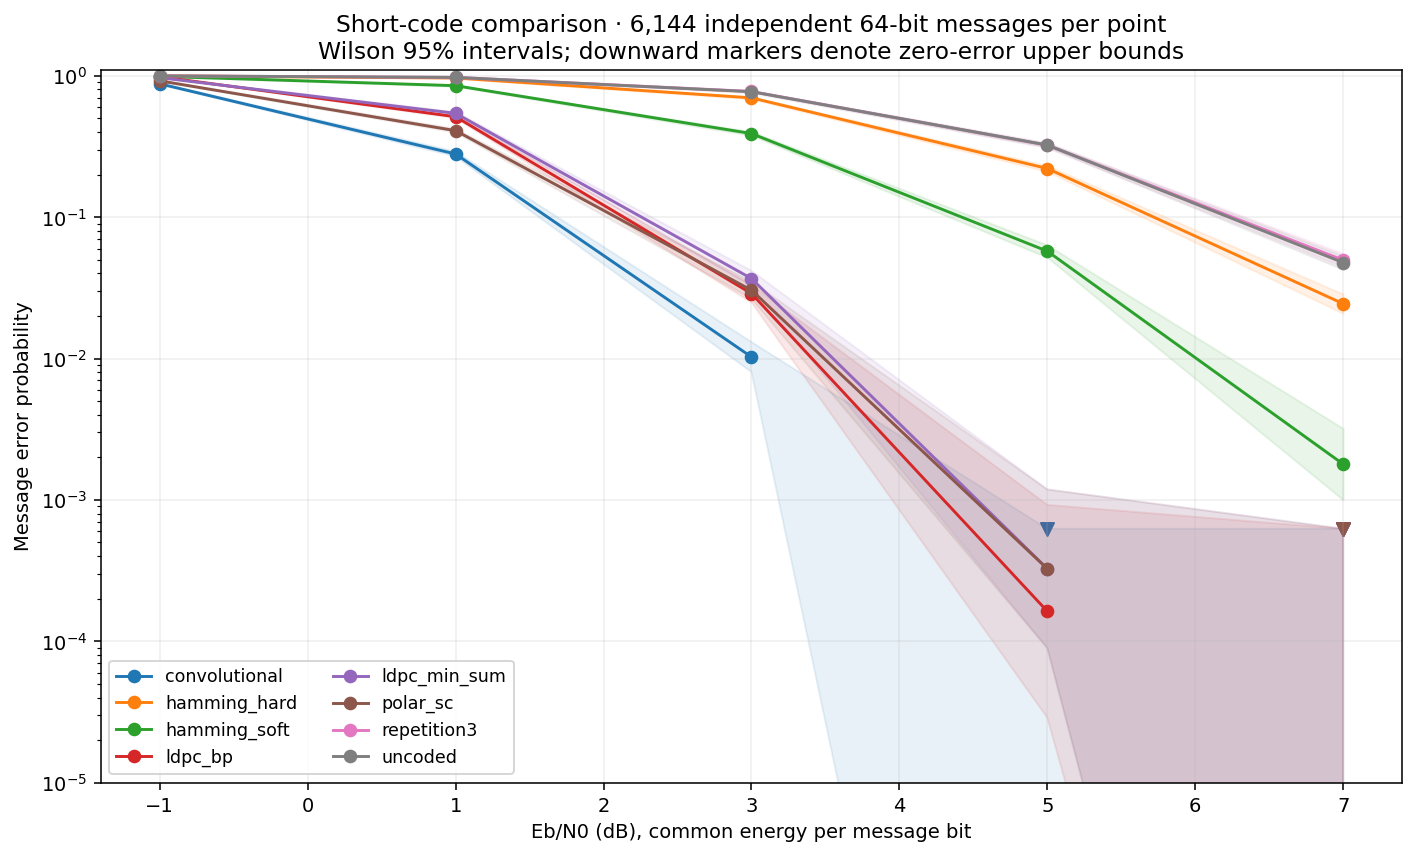

In [5]:
display(Image(filename=str(ROOT / "assets/previews/coding_comparison.png")))

The pooled plot counts independent messages across seeds. A downward marker means zero observed message errors with a nonzero Wilson confidence upper bound. It is not a fabricated small error probability.